Import Library

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from yellowbrick.cluster import KElbowVisualizer
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

In [2]:
data = pd.read_csv('Mall_Customers.csv')
data.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [4]:
data.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


EDA

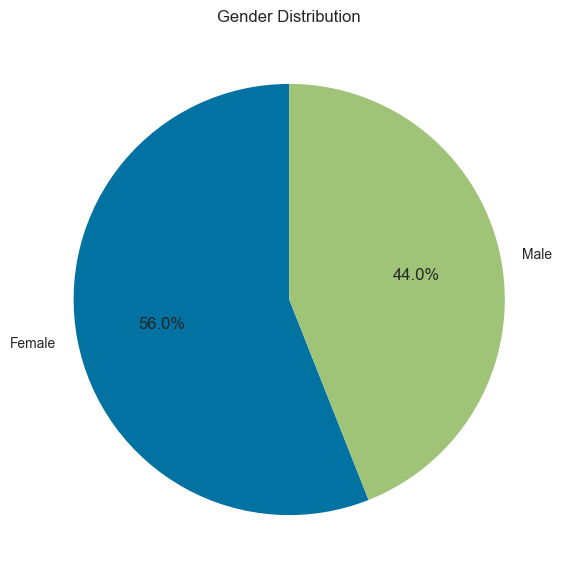

In [5]:
plt.figure(figsize=(7,7))
plt.pie(data['Gender'].value_counts(), labels=['Female', 'Male'], autopct='%1.1f%%', startangle=90)
plt.title('Gender Distribution')
plt.show()

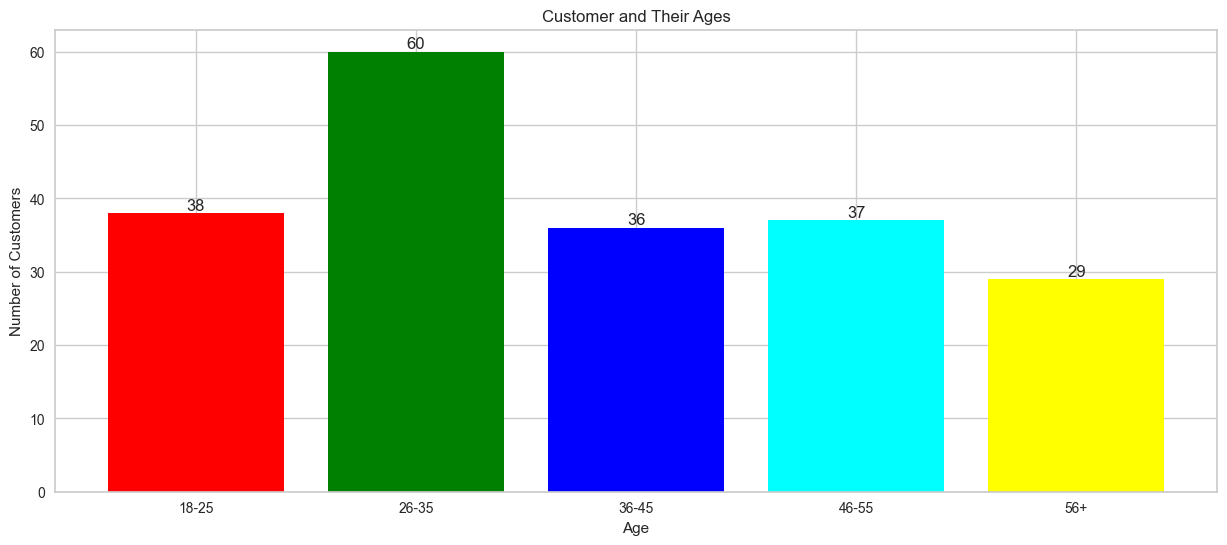

In [6]:
age18_25 = data['Age'][(data.Age >= 18) & (data.Age <= 25)]
age26_35 = data.Age[(data.Age >= 26) & (data.Age <= 35)]
age36_45 = data.Age[(data.Age >= 36) & (data.Age <= 45)]
age46_55 = data.Age[(data.Age >= 46) & (data.Age <= 55)]
age56_above = data.Age[data.Age >= 56]

x = ['18-25', '26-35', '36-45', '46-55', '56+']
y = [len(age18_25), len(age26_35), len(age36_45), len(age46_55), len(age56_above)]

plt.figure(figsize=(15,6))
plt.bar(x,y, color=['red', 'green', 'blue', 'cyan', 'yellow'])
plt.title('Customer and Their Ages')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

for i in range(len(x)):
    plt.text(i, y[i], y[i], ha='center', va='bottom')

plt.show()

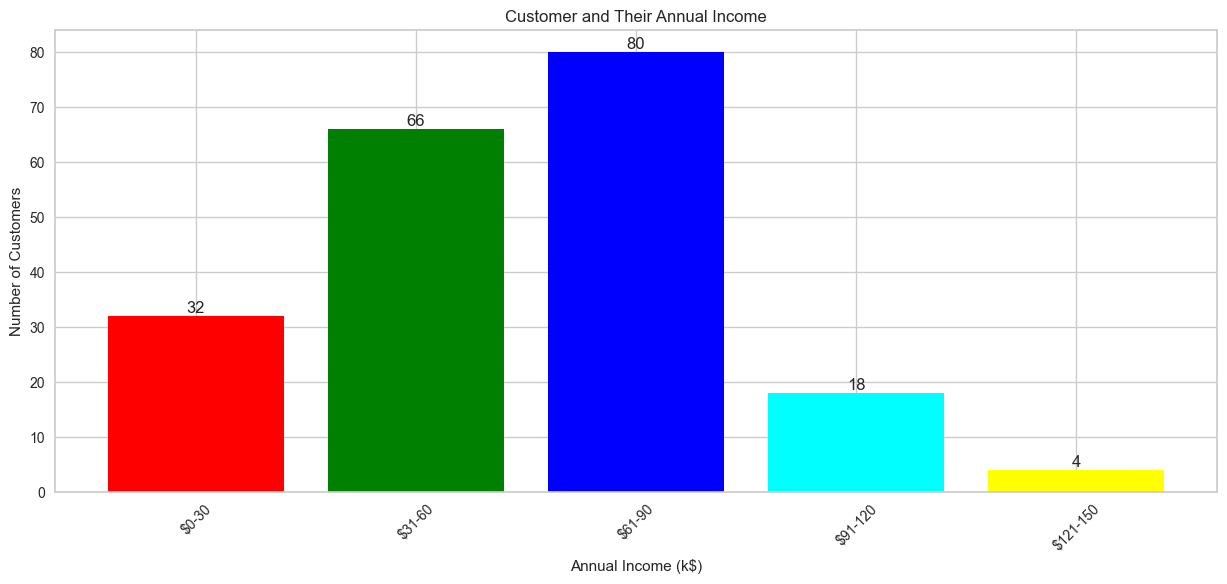

In [11]:
ai0_30 = data['Annual Income (k$)'][(data['Annual Income (k$)'] >= 0) & (data['Annual Income (k$)'] <= 30)]
ai31_60 = data['Annual Income (k$)'][(data['Annual Income (k$)'] >= 31) & (data['Annual Income (k$)'] <= 60)]
ai61_90 = data['Annual Income (k$)'][(data['Annual Income (k$)'] >= 61) & (data['Annual Income (k$)'] <= 90)]
ai91_120 = data['Annual Income (k$)'][(data['Annual Income (k$)'] >= 91) & (data['Annual Income (k$)'] <= 120)]
ai121_150 = data['Annual Income (k$)'][(data['Annual Income (k$)'] >= 121) & (data['Annual Income (k$)'] <= 150)]

aix = ['$0-30', '$31-60', '$61-90', '$91-120', '$121-150']
aiy = [len(ai0_30.values), len(ai31_60.values), len(ai61_90.values), len(ai91_120.values), len(ai121_150.values)]

plt.figure(figsize=(15,6))
plt.bar(aix, aiy, color=['red', 'green', 'blue', 'cyan', 'yellow'])
plt.title('Customer and Their Annual Income')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)

for i in range(len(aix)):
    plt.text(i, aiy[i], aiy[i], ha='center', va='bottom')

plt.show()

Data Splitting


In [16]:
X = data.iloc[:, [3, 4]].values

print(pd.DataFrame(X, columns=['Annual Income (k$)', 'Spending Score (1-100)']))

     Annual Income (k$)  Spending Score (1-100)
0                    15                      39
1                    15                      81
2                    16                       6
3                    16                      77
4                    17                      40
..                  ...                     ...
195                 120                      79
196                 126                      28
197                 126                      74
198                 137                      18
199                 137                      83

[200 rows x 2 columns]


Elbow Method


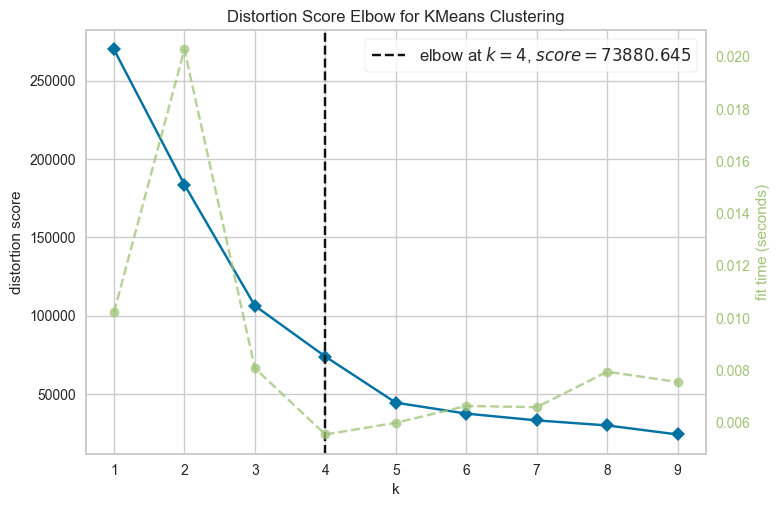

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [22]:
kmeans = KMeans()
visualizer = KElbowVisualizer(kmeans, k=(1,10))
visualizer.fit(X)
visualizer.show()

In [23]:
kmeans = KMeans(n_clusters=4, random_state=0)
kmeans.fit(X)

labels = kmeans.labels_
k = 4

def analyze_clusters(X, labels, k):
    print('Analisis Karakteristik Tiap Cluster: ')
    for cluster_id in range(k):
        cluster_data = X[labels == cluster_id]
        mean_income = cluster_data[:, 0].mean()
        mean_spending = cluster_data[:, 1].mean()

        print(f'Cluster {cluster_id + 1}:')
        print(f'  Rata-rata Pendapatan Tahunan: {mean_income:.2f}')
        print(f'  Rata-rata Skor Pengeluaran: {mean_spending:.2f}')

analyze_clusters(X, labels, k)

Analisis Karakteristik Tiap Cluster: 
Cluster 1:
  Rata-rata Pendapatan Tahunan: 48.26
  Rata-rata Skor Pengeluaran: 56.48
Cluster 2:
  Rata-rata Pendapatan Tahunan: 86.54
  Rata-rata Skor Pengeluaran: 82.13
Cluster 3:
  Rata-rata Pendapatan Tahunan: 87.00
  Rata-rata Skor Pengeluaran: 18.63
Cluster 4:
  Rata-rata Pendapatan Tahunan: 26.30
  Rata-rata Skor Pengeluaran: 20.91


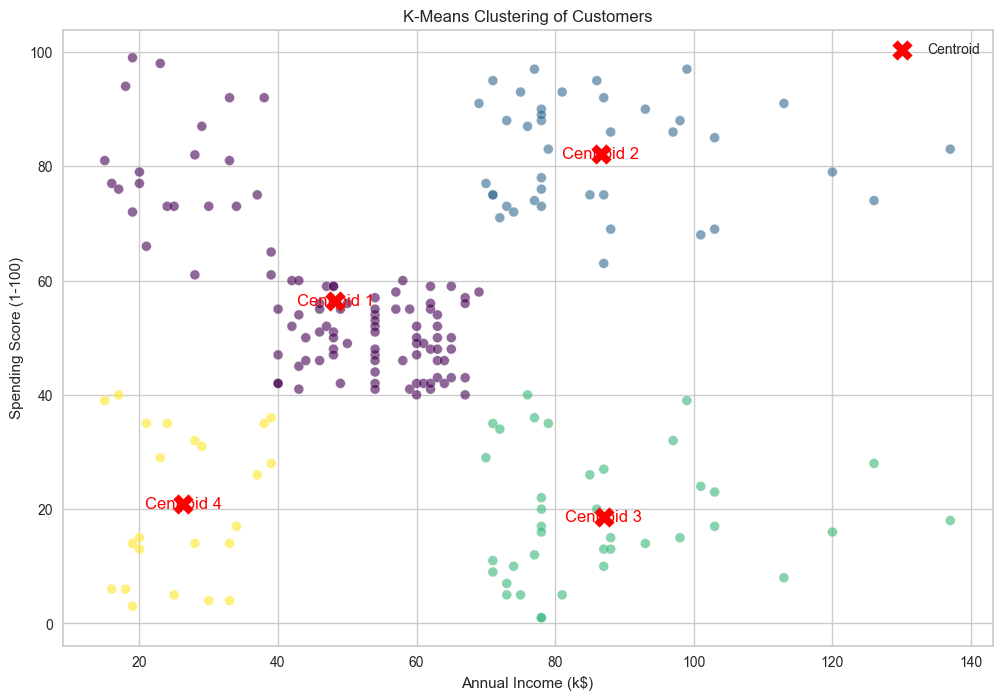

In [24]:
centroids = kmeans.cluster_centers_

plt.figure(figsize=(12,8))

plt.scatter(X[:, 0], X[:, 1], c=labels,alpha=0.6, cmap='viridis', marker='o', edgecolor='w', s=50)
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=200, label='Centroid')

for i, centroid in enumerate(centroids):
    plt.text(centroid[0], centroid[1], f'Centroid {i+1}', color='red', fontsize=12, ha='center', va='center')

plt.title('K-Means Clustering of Customers')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()

plt.show()

In [31]:
income = input('Masukkan income pertahun (dalam k$): ')
score = input('Masukkan spending score (1-100): ')
new_data = [[float(income), float(score)]]
predicted_cluster = kmeans.predict(new_data)
print(f"Income : {income} k$, Spending Score: {score}")
print(f'Customer tersebut termasuk ke dalam cluster: {predicted_cluster[0] + 1}')

Income : 80 k$, Spending Score: 90
Customer tersebut termasuk ke dalam cluster: 2


In [ ]:
#done